In [1]:
print('Hello World')


Hello World


In [3]:
import pandas as pd
covid_data= pd.read_csv('https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_daily_reports/03-17-2020.csv')

In [3]:
covid_data.head()

,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered,Latitude,Longitude
0,Hubei,China,2020-03-17T11:53:10,67799,3111,56003,30.9756,112.2707
1,NaN,Italy,2020-03-17T18:33:02,31506,2503,2941,41.8719,12.5674
2,NaN,Iran,2020-03-17T15:13:09,16169,988,5389,32.4279,53.6880
3,NaN,Spain,2020-03-17T20:53:02,11748,533,1028,40.4637,-3.7492
4,NaN,Germany,2020-03-17T18:53:02,9257,24,67,51.1657,10.4515


In [4]:
print(covid_data)

       Province/State  Country/Region          Last Update  Confirmed  Deaths  \
0               Hubei           China  2020-03-17T11:53:10      67799    3111   
1                 NaN           Italy  2020-03-17T18:33:02      31506    2503   
2                 NaN            Iran  2020-03-17T15:13:09      16169     988   
3                 NaN           Spain  2020-03-17T20:53:02      11748     533   
4                 NaN         Germany  2020-03-17T18:53:02       9257      24   
..                ...             ...                  ...        ...     ...   
307             Wales  United Kingdom  2020-03-17T11:53:10          0       5   
308               NaN           Nauru  2020-03-17T11:53:10          0       0   
309              Niue     New Zealand  2020-03-17T11:53:10          0       0   
310               NaN          Tuvalu  2020-03-17T11:53:10          0       0   
311  Pitcairn Islands  United Kingdom  2020-03-17T11:53:10          0       0   

     Recovered  Latitude  L

In [5]:
# dataset information

print(covid_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  154 non-null    object 
 1   Country/Region  312 non-null    object 
 2   Last Update     312 non-null    object 
 3   Confirmed       312 non-null    int64  
 4   Deaths          312 non-null    int64  
 5   Recovered       312 non-null    int64  
 6   Latitude        309 non-null    float64
 7   Longitude       309 non-null    float64
dtypes: float64(2), int64(3), object(3)
memory usage: 19.6+ KB
None


In [6]:
# missing data information

print(covid_data.isna().sum())

Province/State    158
Country/Region      0
Last Update         0
Confirmed           0
Deaths              0
Recovered           0
Latitude            3
Longitude           3
dtype: int64


In [15]:
covid_data['Active'] = covid_data['Confirmed'] - covid_data['Deaths'] - covid_data['Recovered']

result = covid_data.groupby('Country/Region')[['Confirmed', 'Deaths', 'Recovered', 'Active']].sum().reset_index()

print(result)

#covid_data.head(20)

                     Country/Region  Confirmed  Deaths  Recovered  Active
0                       Afghanistan         26       0          1      25
1                           Albania         55       1          0      54
2                           Algeria         60       4         12      44
3                           Andorra         39       0          1      38
4                        Antarctica          0       0          0       0
..                              ...        ...     ...        ...     ...
163                      Uzbekistan         10       0          0      10
164                       Venezuela         33       0          0      33
165                         Vietnam         66       0         16      50
166            Winter Olympics 2022          0       0          0       0
167  occupied Palestinian territory          0       0          0       0

[168 rows x 5 columns]


In [26]:
zeros_recovered = covid_data[covid_data['Recovered'] == 0] ['Country/Region'].unique()
zeros_recovered


array(['US', 'Slovenia', 'Iceland', 'Chile', 'Luxembourg', 'Canada',
       'Slovakia', 'Panama', 'Bulgaria', 'South Africa', 'Ecuador',
       'Brunei', 'Albania', 'Denmark', 'Turkey', 'Cyprus', 'Costa Rica',
       'Kazakhstan', 'Venezuela', 'Australia', 'Uruguay', 'Tunisia',
       'Dominican Republic', 'Guadeloupe', 'Martinique', 'Burkina Faso',
       'Ukraine', 'Maldives', 'New Zealand', 'Bolivia', 'French Guiana',
       'Cameroon', 'Uzbekistan', 'France', 'Paraguay', 'Reunion',
       'Honduras', 'Ghana', 'Guyana', 'Liechtenstein', 'Monaco', 'Rwanda',
       'Guatemala', 'United Kingdom', 'Cuba', 'Ethiopia', 'Mongolia',
       'Trinidad and Tobago', 'Seychelles', 'Aruba', 'Congo (Kinshasa)',
       'Guam', 'Kenya', 'Netherlands', 'Nigeria', 'Barbados', 'Kosovo',
       'Montenegro', 'Namibia', 'Saint Lucia', 'Antigua and Barbuda',
       'Benin', 'Bhutan', 'Central African Republic',
       'Congo (Brazzaville)', 'Equatorial Guinea', 'Eswatini', 'Gabon',
       'Greenland', 'Gu

In [27]:
zeros_recovered = covid_data.groupby('Country/Region')[['Confirmed', 'Deaths', 'Recovered']].sum().reset_index()
zeros_recovered

,Country/Region,Confirmed,Deaths,Recovered
0,Afghanistan,26,0,1
1,Albania,55,1,0
2,Algeria,60,4,12
3,Andorra,39,0,1
4,Antarctica,0,0,0
...,...,...,...,...
163,Uzbekistan,10,0,0
164,Venezuela,33,0,0
165,Vietnam,66,0,16
166,Winter Olympics 2022,0,0,0


In [29]:
data = covid_data.groupby(['Country/Region', 'Province/State']) [['Confirmed', 'Deaths', 'Recovered']].max()
pd.set_option = ('display.max_rows', None)
print(data)

                                             Confirmed  Deaths  Recovered
Country/Region Province/State                                            
Australia      Australian Capital Territory          2       0          0
               From Diamond Princess                 0       0          0
               New South Wales                     210       4          4
               Northern Territory                    1       0          0
               Queensland                           78       0          8
...                                                ...     ...        ...
United Kingdom Northern Ireland                      0       0          0
               Pitcairn Islands                      0       0          0
               Scotland                              0      11          0
               Unknown                            1950       2         52
               Wales                                 0       5          0

[154 rows x 3 columns]


In [30]:
chinese_data = covid_data[covid_data['Country/Region'] == 'China']
chinese_data = chinese_data[['Province/State', 'Confirmed', 'Deaths', 'Recovered']]
result = chinese_data.sort_values(by = 'Confirmed', ascending = False)
result = result.reset_index(drop = True)
print(result)

    Province/State  Confirmed  Deaths  Recovered
0            Hubei      67799    3111      56003
1        Guangdong       1364       8       1307
2            Henan       1273      22       1250
3         Zhejiang       1232       1       1216
4            Hunan       1018       4       1014
5            Anhui        990       6        984
6          Jiangxi        935       1        934
7         Shandong        761       7        746
8          Jiangsu        631       0        631
9        Chongqing        576       6        570
10         Sichuan        540       3        520
11    Heilongjiang        482      13        456
12         Beijing        456       8        369
13        Shanghai        358       3        325
14           Hebei        318       6        310
15          Fujian        296       1        295
16         Guangxi        253       2        248
17         Shaanxi        246       3        236
18          Yunnan        176       2        172
19          Hainan  

In [40]:
result = covid_data[covid_data['Deaths']>0].groupby('Country/Region')['Deaths'].sum().reset_index()
print(result)

        Country/Region  Deaths
0              Albania       1
1              Algeria       4
2            Argentina       2
3            Australia       5
4              Austria       3
5           Azerbaijan       1
6              Bahrain       1
7              Belgium      10
8               Brazil       1
9             Bulgaria       2
10              Canada       6
11               China    3230
12         Cruise Ship       7
13             Denmark       4
14  Dominican Republic       1
15             Ecuador       2
16               Egypt       4
17             Finland       4
18              France     148
19             Germany      24
20              Greece       5
21           Guatemala       1
22              Guyana       1
23             Hungary       1
24             Iceland       1
25               India       3
26           Indonesia       5
27                Iran     988
28                Iraq      11
29             Ireland       2
30               Italy    2503
31      

In [42]:
# This is a test for my git troubleshooting process

print('This is a test for my git troubleshooting process')

This is a test for my git troubleshooting process


In [48]:
# No cases recovered

result = covid_data[covid_data['Recovered'] == 0].groupby('Country/Region') ['Recovered'].sum().reset_index()
print(result)

                    Country/Region  Recovered
0                          Albania          0
1                       Antarctica          0
2              Antigua and Barbuda          0
3                            Aruba          0
4                        Australia          0
..                             ...        ...
93                         Uruguay          0
94                      Uzbekistan          0
95                       Venezuela          0
96            Winter Olympics 2022          0
97  occupied Palestinian territory          0

[98 rows x 2 columns]


In [54]:
# All Cases Dead
data = covid_data.groupby('Country/Region') [['Confirmed', 'Deaths', 'Recovered']].sum().reset_index()
result = data[data['Confirmed'] == data['Deaths']]
result = result.sort_values('Confirmed', ascending = False)
result = result[result ['Confirmed'] > 0]
result = result.reset_index(drop = True)
print(result)

  Country/Region  Confirmed  Deaths  Recovered
0          Sudan          1       1          0


In [55]:
# All Cases Recovered
result = data[data['Confirmed'] == data['Recovered']]
result = result.sort_values('Confirmed', ascending = False)
result = result[result['Confirmed'] > 0]
result = result.reset_index(drop = True)
print(result)

  Country/Region  Confirmed  Deaths  Recovered
0          Nepal          1       0          1


In [56]:
# Github won't count my contribution today

print("Github won't count my contribution today")

Github won't count my contribution today


In [1]:
# Github won't count my contribution today

print("Github won't count my contribution today")

Github won't count my contribution today


In [ ]:
# top 10 Countries data of Covid
result = covid_data.groupby('Country/Region').max(numeric_only = True).sort_values(by = 'Confirmed', ascending = False) [:10]
pd.set_option('display.max_column', None)
print(result)

                Confirmed  Deaths  Recovered  Latitude  Longitude
Country/Region                                                   
China               67799    3111      56003   47.8620   127.7615
Italy               31506    2503       2941   41.8719    12.5674
Iran                16169     988       5389   32.4279    53.6880
Spain               11748     533       1028   40.4637    -3.7492
Germany              9257      24         67   51.1657    10.4515
Korea, South         8320      81       1407   35.9078   127.7669
France               7652     148         12   46.2276    55.2471
Switzerland          2700      40          4   46.8182     8.2275
United Kingdom       1950     198         52   56.4907    -1.1743
US                   1706      55          6   61.3707   144.7937


Text(0.5, 1.0, 'Total Deaths(>150), Confirmed, Recovered and Active Cases by Country')

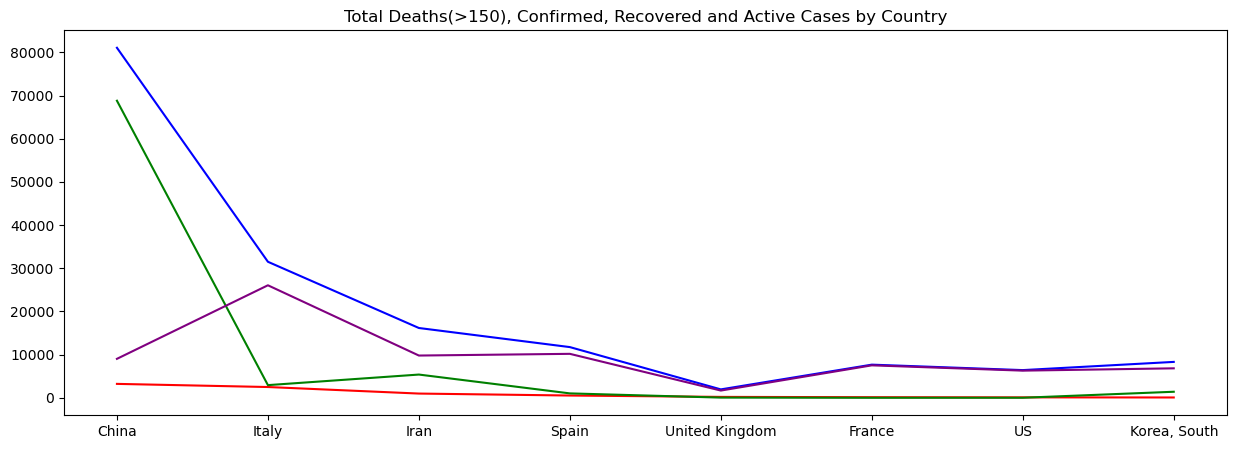

In [ ]:
import matplotlib.pyplot as plt

#plot of total deaths, confirmed, recovered and active cases Country wise where deaths greater than 150
covid_data['Active'] = covid_data['Confirmed'] - covid_data['Recovered'] - covid_data['Deaths']
data = covid_data.groupby('Country/Region') [['Deaths', 'Confirmed', 'Recovered', 'Active']].sum().reset_index()
result = data[data['Deaths']> 50]
result = result.sort_values(by  = 'Deaths', ascending=False)

plt.figure(figsize=(15, 5))
plt.plot(result['Country/Region'], result['Deaths'], 'red')
plt.plot(result['Country/Region'], result['Confirmed'], 'blue')
plt.plot(result['Country/Region'], result['Recovered'], 'green')
plt.plot(result['Country/Region'], result['Active'], 'purple')
#x = [['Deaths', 'Confirmed', 'Recovered', 'Active']]
#y = ['Country/Region']

plt.title('Total Deaths(>150), Confirmed, Recovered and Active Cases by Country')


